<a href="https://colab.research.google.com/github/aydargor12-oss/mnist-digit-recognition/blob/main/MNIST_Multiclass_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [22]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix
import seaborn as sns


import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

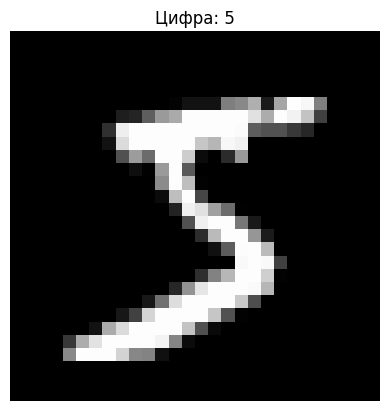

In [ ]:
plt.imshow(x_train[0], cmap="grey")
plt.title(f"Цифра: {y_train[0]}")
plt.axis("off")
plt.show()

In [ ]:
# ЗАГРУЖАЕМ КАРТИНКИ МАТ. ОПЕРАЦИЙ И ДОПОЛНИТЕЛЬНЫЕ ЦИФРЫ
!git clone https://github.com/wblachowski/bhmsds.git

data_dir = "bhmsds/symbols"

files = os.listdir(data_dir)

target_classes = [
    "0", "1", "2", "3", "4",
    "5", "6", "7", "8", "9",
    "plus", "minus", "x", "slash", "dot"
]

images = []
labels = []

for class_index, class_name in enumerate(target_classes):

    class_files = [f for f in files if f.split("-")[0] == class_name]

    for filename in class_files:

        image_path = os.path.join(data_dir, filename)

        image = tf.io.read_file(image_path)

        image = tf.image.decode_png(image, channels=1)

        image = tf.cast(image, tf.float32)

        image = 255.0 - image

        image = image / 255.0

        images.append(image.numpy())
        labels.append(class_index)


images = np.array(images, dtype=np.float32)
labels = np.array(labels, dtype=np.int64)

print("Форма изображений:", images.shape)
print("Форма меток:", labels.shape)
print("Диапазон пикселей:", images.min(), "-", images.max())
print("Количество классов:", len(np.unique(labels)))

Cloning into 'bhmsds'...
remote: Enumerating objects: 27038, done.
remote: Counting objects: 100% (36/36), done.
remote: Compressing objects: 100% (27/27), done.
remote: Total 27038 (delta 8), reused 32 (delta 6), pack-reused 27002 (from 1)
Receiving objects: 100% (27038/27038), 11.37 MiB | 15.40 MiB/s, done.
Resolving deltas: 100% (8/8), done.
Updating files: 100% (27003/27003), done.
Форма изображений: (22500, 28, 28, 1)
Форма меток: (22500,)
Диапазон пикселей: 0.0 - 1.0
Количество классов: 15


In [ ]:
x_train = x_train.astype(np.float32) / 255.0
x_test = x_test.astype(np.float32) / 255.0

x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print("Обучающая выборка", x_train.shape)
print("Тестовая выборка:", x_test.shape)
print("Тип данных:", x_train.dtype)
print("Диапазон значений:", x_train.min(), "-", x_train.max())

Обучающая выборка (60000, 28, 28, 1)
Тестовая выборка: (10000, 28, 28, 1)
Тип данных: float32
Диапазон значений: 0.0 - 1.0


In [ ]:
images_train, images_temp, labels_train, labels_temp = train_test_split(
    images,
    labels,
    test_size=0.2,
    stratify=labels
)

images_val, images_test, labels_val, labels_test = train_test_split(
    images_temp,
    labels_temp,
    test_size=0.5,
    stratify=labels_temp
)


print("Train:", images_train.shape, labels_train.shape)
print("Validation:", images_val.shape, labels_val.shape)
print("Test:", images_test.shape, labels_test.shape)

Train: (18000, 28, 28, 1) (18000,)
Validation: (2250, 28, 28, 1) (2250,)
Test: (2250, 28, 28, 1) (2250,)


In [ ]:
x_mnist_train, x_mnist_val, y_mnist_train, y_mnist_val = train_test_split(
    x_train,
    y_train,
    test_size=0.1,
    stratify=y_train
)

print("MNIST Train:", x_mnist_train.shape, y_mnist_train.shape)
print("MNIST Validation:", x_mnist_val.shape, y_mnist_val.shape)
print("MNIST Test:", x_test.shape, y_test.shape)

MNIST Train: (54000, 28, 28, 1) (54000,)
MNIST Validation: (6000, 28, 28, 1) (6000,)
MNIST Test: (10000, 28, 28, 1) (10000,)


In [ ]:
# ОБЪЕДИНЯЕМ ОБУЧАЮЩИЕ ИЗОБРАЖЕНИЯ

x_combined_train = np.concatenate(
    [x_mnist_train, images_train],
    axis=0
)

y_combined_train = np.concatenate(
    [y_mnist_train, labels_train],
    axis=0
)

# ОБЪЕДИНЯЕМ ВАЛИДАЦИОННЫЕ ДАННЫЕ

x_combined_val = np.concatenate(
    [x_mnist_val, images_val],
    axis=0
)

y_combined_val = np.concatenate(
    [y_mnist_val, labels_val],
    axis=0
)


print("Train:", x_combined_train.shape, y_combined_train.shape)
print("Validation:", x_combined_val.shape, y_combined_val.shape)

print("Количество классов:", len(np.unique(y_combined_train)))
print("Тип данных:", x_combined_train.dtype)

Train: (72000, 28, 28, 1) (72000,)
Validation: (8250, 28, 28, 1) (8250,)
Количество классов: 15
Тип данных: float32


In [ ]:
unique, counts = np.unique(y_combined_train, return_counts=True)

for class_name, count in zip(target_classes, counts):
    print(f"{class_name}: {count}")

0: 6531
1: 7268
2: 6562
3: 6718
4: 6458
5: 6079
6: 6526
7: 6838
8: 6466
9: 6554
plus: 1200
minus: 1200
x: 1200
slash: 1200
dot: 1200


In [ ]:
classes = np.unique(y_combined_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_combined_train
)

class_weights = dict(zip(classes, weights))

for class_index, weight in class_weights.items():
  print(f"{target_classes[class_index]}: {weight:.3f}")

0: 0.735
1: 0.660
2: 0.731
3: 0.714
4: 0.743
5: 0.790
6: 0.736
7: 0.702
8: 0.742
9: 0.732
plus: 4.000
minus: 4.000
x: 4.000
slash: 4.000
dot: 4.000


In [ ]:
model_combined = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPool2D((2,2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPool2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(15, activation="softmax")
])

In [ ]:
model_combined.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │           975 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,255 (477.56 KB)

 Trainable params: 122,255 (477.56 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model_combined.compile(
    optimizer="adam",
    loss='sparse_categorical_crossentropy',
    metrics=["accuracy"]
)

In [ ]:
history = model_combined.fit(
    x_combined_train,
    y_combined_train,
    validation_data=(x_combined_val, y_combined_val),
    epochs=10,
    batch_size=64,
    class_weight=class_weights
)

Epoch 1/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 60s 51ms/step - accuracy: 0.9163 - loss: 0.2485 - val_accuracy: 0.9674 - val_loss: 0.1074
Epoch 2/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 52s 46ms/step - accuracy: 0.9749 - loss: 0.0708 - val_accuracy: 0.9802 - val_loss: 0.0678
Epoch 3/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 52s 46ms/step - accuracy: 0.9837 - loss: 0.0433 - val_accuracy: 0.9790 - val_loss: 0.0674
Epoch 4/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 82s 46ms/step - accuracy: 0.9864 - loss: 0.0347 - val_accuracy: 0.9822 - val_loss: 0.0625
Epoch 5/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 83s 47ms/step - accuracy: 0.9894 - loss: 0.0278 - val_accuracy: 0.9847 - val_loss: 0.0492
Epoch 6/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 80s 46ms/step - accuracy: 0.9918 - loss: 0.0213 - val_accuracy: 0.9856 - val_loss: 0.0574
Epoch 7/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 54s 48ms/step - accuracy: 0.9931 - loss: 0.0183 - val_accuracy: 0.9887 - val_loss: 0.0505
Epoch 8/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 51s 46ms/step - accuracy: 0.9940 -

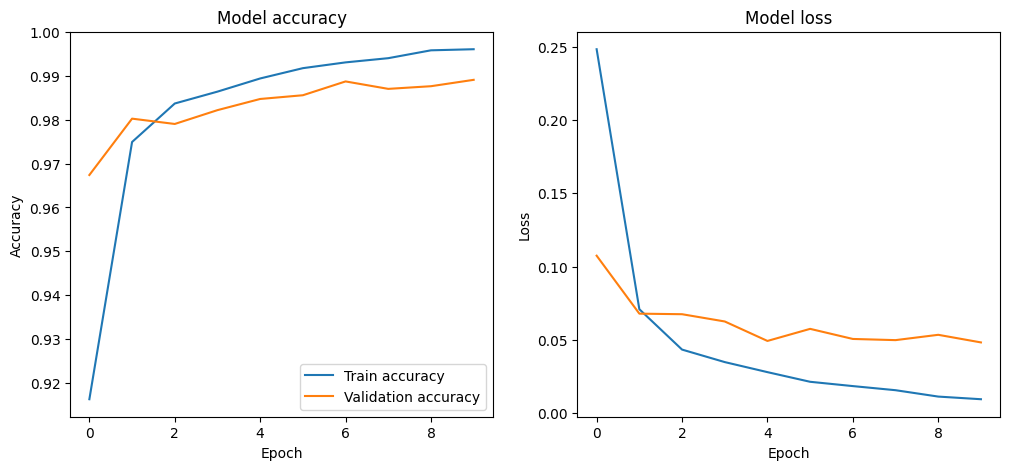

In [ ]:
plt.figure(figsize=(12,5))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.title("Model accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()


plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("Model loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

In [ ]:
mnist_results = model_combined.evaluate(
    x_test,
    y_test,
    verbose=0
)

bhmsds_results = model_combined.evaluate(
    images_test,
    labels_test,
    verbose=0
)

print("\nMNIST test:", mnist_results[1])
print("BHMSDS test:", bhmsds_results[1])


MNIST test: 0.9912999868392944
BHMSDS test: 0.9826666712760925


313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step


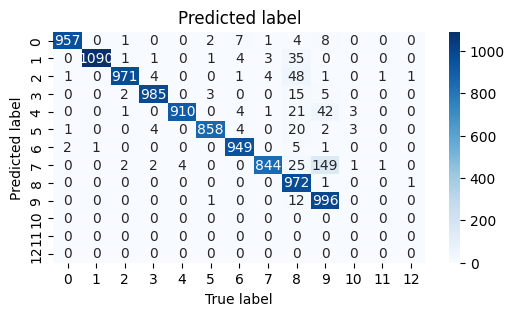

In [26]:
y_pred_mnist = model_combined.predict(x_test)
y_pred_mnist = np.argmax(y_pred_mnist, axis=1)


cm_mnist = confusion_matrix(y_test, y_pred_mnist)

plt.figure(figsize=(6, 3))

sns.heatmap(
    cm_mnist,
    annot=True,
    fmt="d",
    cmap="Blues"
)
plt.xlabel("True label")
plt.ylabel("Predicted label")
plt.title("Predicted label")
plt.show()
